# Práctica 4 - Anatomía de un dataset de Machine Learning
**Sesión 4 - El dataset**

## Objetivos
Analizar un dataset desde el punto de vista de Machine Learning: muestras, variables, identificadores, características, target, \(X\), \(y\), tipos conceptuales, valores ausentes y distribuciones.

> El objetivo principal no es escribir mucho código, sino **interpretar correctamente los datos**.

## Contexto
Una plataforma de comercio electrónico dispone de información histórica sobre sus clientes. Trabajaremos con `clientes_ecommerce.csv`.

| Variable | Descripción |
|---|---|
| `cliente_id` | Identificador único |
| `edad` | Edad |
| `antiguedad_meses` | Meses desde el registro |
| `ingresos_anuales` | Ingresos anuales estimados |
| `gasto_mensual` | Gasto medio mensual |
| `num_compras` | Compras del último año |
| `devoluciones` | Devoluciones del último año |
| `dispositivo` | Dispositivo principal |
| `zona` | Zona de residencia |
| `nivel_fidelidad` | Bronce, Plata, Oro o Platino |
| `satisfaccion` | Valoración de 1 a 5 |
| `compra_proximo_mes` | Compra el mes siguiente: Sí/No |

Completa las celdas `# TODO` y responde en Markdown.

## Preparación

In [1]:
# TODO: importa NumPy, pandas y matplotlib.pyplot
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# TODO: carga clientes_ecommerce.csv en df
df = pd.read_csv("clientes_ecommerce.csv")

## Parte 1 - Comprender el dataset
### Ejercicio 1 - Primera inspección
Muestra las primeras 10 filas.

In [2]:
# TODO: muestra las primeras 10 filas
df.head(10)

,cliente_id,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,dispositivo,zona,nivel_fidelidad,satisfaccion,compra_proximo_mes
0,20001,67,102.0,9000.00,60.73,7,3,Móvil,Oeste,Oro,5,No
1,20002,28,93.0,35683.86,131.74,6,1,Móvil,Este,Bronce,2,No
2,20003,19,87.0,37152.19,55.33,8,1,Ordenador,Este,Plata,5,Sí
3,20004,55,79.0,40158.29,24.33,7,0,Ordenador,Norte,Bronce,4,Sí
4,20005,39,3.0,27317.06,88.78,5,0,Móvil,Sur,Bronce,4,No
5,20006,45,25.0,32627.01,59.77,9,2,Móvil,Este,Bronce,5,No
6,20007,22,105.0,44101.68,109.67,8,0,Móvil,Norte,Oro,5,Sí
7,20008,39,90.0,44882.10,57.56,7,2,Ordenador,Norte,Plata,2,Sí
8,20009,55,56.0,55299.19,49.94,6,2,Móvil,Sur,Bronce,5,No
9,20010,38,93.0,9000.00,110.69,10,2,Ordenador,Centro,Oro,4,Sí


### Respuesta
1. ¿Qué representa una fila?
2. ¿Qué representa una columna?
3. ¿Cuál es la unidad de observación?
4. ¿Todas las columnas son características? Justifica.

**Respuesta:**

1. Un cliente con todos sus datos.
2. Una variable, por ejemplo la edad o el gasto mensual.
3. El cliente.
4. No. cliente_id solo sirve para identificar a cada cliente y compra_proximo_mes es lo que queremos predecir, así que ninguna de las dos es una característica. Las otras 10 sí.

### Ejercicio 2 - Dimensiones
Obtén `df.shape`.

In [3]:
# TODO: consulta las dimensiones
df.shape

(400, 12)

### Respuesta
- Número de muestras: 400
- Número de columnas: 12
- ¿Tenemos el mismo número de características? ¿Por qué?

No, tenemos 10 características porque hay que quitar cliente_id y compra_proximo_mes.

## Parte 2 - Clasificación de variables
### Ejercicio 3 - Tipos almacenados

In [4]:
# TODO: consulta df.dtypes
df.dtypes

cliente_id              int64
edad                    int64
antiguedad_meses      float64
ingresos_anuales      float64
gasto_mensual         float64
num_compras             int64
devoluciones            int64
dispositivo               str
zona                      str
nivel_fidelidad           str
satisfaccion            int64
compra_proximo_mes        str
dtype: object

### Ficha de variables
Clasifica cada variable como: **Identificador, Numérica discreta, Numérica continua, Categórica nominal, Categórica ordinal o Target**.

| Variable | dtype | Tipo conceptual | ¿Feature candidata? |
|---|---|---|---|
| cliente_id | int64 | Identificador | No |
| edad | int64 | Numérica discreta | Sí |
| antiguedad_meses | float64 | Numérica discreta (sale float por los NaN) | Sí |
| ingresos_anuales | float64 | Numérica continua | Sí |
| gasto_mensual | float64 | Numérica continua | Sí |
| num_compras | int64 | Numérica discreta | Sí |
| devoluciones | int64 | Numérica discreta | Sí |
| dispositivo | str | Categórica nominal | Sí |
| zona | str | Categórica nominal | Sí |
| nivel_fidelidad | str | Categórica ordinal | Sí |
| satisfaccion | int64 | Categórica ordinal | Sí |
| compra_proximo_mes | str | Target | No |

No clasifiques únicamente por `dtype`.

### Ejercicio 4 - `cliente_id`
Muestra sus primeros 10 valores.

In [5]:
# TODO: analiza cliente_id
print(df["cliente_id"].head(10))
print("dtype:", df["cliente_id"].dtype)
print("Valores únicos:", df["cliente_id"].nunique(), "de", len(df))

0    20001
1    20002
2    20003
3    20004
4    20005
5    20006
6    20007
7    20008
8    20009
9    20010
Name: cliente_id, dtype: int64
dtype: int64
Valores únicos: 400 de 400


### Respuesta
1. ¿Qué dtype tiene?
2. ¿Es por ello cuantitativa?
3. ¿Tiene sentido calcular su media?
4. ¿La incluirías inicialmente en \(X\)?
5. Justifica.
###
1. int64
2. No, es un número pero no mide nada.
3. No, la media de los id (20200.5) no significa nada.
4. No.
5. Cada cliente tiene un id distinto (van del 20001 al 20400) y está puesto a dedo, así que no dice nada de cómo es el cliente. Si lo metemos el modelo podría aprender cosas sin sentido con él.

### Ejercicio 5 - `satisfaccion`
Muestra la frecuencia de sus valores ordenados.

In [6]:
# TODO: value_counts() + sort_index()
df["satisfaccion"].value_counts().sort_index()

satisfaccion
1     33
2     58
3    123
4    116
5     70
Name: count, dtype: int64

Sabemos que 1 = Muy insatisfecho, 2 = Insatisfecho, 3 = Neutral, 4 = Satisfecho y 5 = Muy satisfecho.

### Respuesta
1. ¿Cómo la almacena pandas?
2. ¿Es simplemente numérica?
3. ¿Existe un orden?
4. ¿Nominal u ordinal?
5. Explica `dtype` frente a significado conceptual.
###
1. Como int64.
2. No, los números son como etiquetas de una valoración.
3. Sí, de 1 (muy insatisfecho) a 5 (muy satisfecho).
4. Ordinal, porque hay orden pero no sabemos si de 1 a 2 hay la misma distancia que de 4 a 5.
5. El dtype es solo cómo guarda pandas el dato, pero lo que importa es lo que significa. Aquí se guarda como número pero en realidad es una categoría con orden.

## Parte 3 - Calidad de los datos
### Ejercicio 6 - Información estructural

In [7]:
# TODO: utiliza df.info()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   cliente_id          400 non-null    int64  
 1   edad                400 non-null    int64  
 2   antiguedad_meses    395 non-null    float64
 3   ingresos_anuales    396 non-null    float64
 4   gasto_mensual       397 non-null    float64
 5   num_compras         400 non-null    int64  
 6   devoluciones        400 non-null    int64  
 7   dispositivo         400 non-null    str    
 8   zona                400 non-null    str    
 9   nivel_fidelidad     400 non-null    str    
 10  satisfaccion        400 non-null    int64  
 11  compra_proximo_mes  400 non-null    str    
dtypes: float64(3), int64(5), str(4)
memory usage: 37.6 KB


### Respuesta
1. ¿Cuántas muestras hay?
2. ¿Qué tipos técnicos aparecen?
3. ¿Todas las columnas tienen los mismos valores no nulos?
4. ¿Qué columnas contienen ausentes?
5. ¿Cuántos faltan?

### 

1. 400.
2. int64 (5 columnas), float64 (3) y str (4).
3. No.
4. antiguedad_meses, ingresos_anuales y gasto_mensual.
5. Faltan 5, 4 y 3, en total 12.

### Ejercicio 7 - Valores ausentes
Calcula cantidad y porcentaje por columna.

In [8]:
# TODO: valores ausentes por columna
ausentes = df.isna().sum()
print(ausentes)

# TODO: porcentaje de ausentes por columna
porcentaje = (df.isna().mean() * 100).round(2)
print(porcentaje)

cliente_id            0
edad                  0
antiguedad_meses      5
ingresos_anuales      4
gasto_mensual         3
num_compras           0
devoluciones          0
dispositivo           0
zona                  0
nivel_fidelidad       0
satisfaccion          0
compra_proximo_mes    0
dtype: int64
cliente_id            0.00
edad                  0.00
antiguedad_meses      1.25
ingresos_anuales      1.00
gasto_mensual         0.75
num_compras           0.00
devoluciones          0.00
dispositivo           0.00
zona                  0.00
nivel_fidelidad       0.00
satisfaccion          0.00
compra_proximo_mes    0.00
dtype: float64


### Reflexión
¿Es lo mismo que falten 5 valores entre 50 muestras que entre 100.000? ¿Por qué son útiles los porcentajes?

No. 5 de 50 es un 10%, que es bastante, pero 5 de 100.000 no es casi nada. Por eso los porcentajes ayudan, porque así se puede ver si el problema es grande o no y comparar entre columnas o datasets de distinto tamaño. En este dataset faltan muy pocos (1.25%, 1% y 0.75%).

## Parte 4 - Construcción de X e y
Queremos predecir: **¿realizará el cliente una compra el próximo mes?**

### Ejercicio 8 - Variable objetivo

In [9]:
# TODO: crea y
y = df["compra_proximo_mes"]

# TODO: muestra y.head() y y.shape
print(y.head())
print(y.shape)

0    No
1    No
2    Sí
3    Sí
4    No
Name: compra_proximo_mes, dtype: str
(400,)


### Respuesta
1. ¿Qué representa cada elemento de \(y\)?
2. ¿Cuántos contiene?
3. ¿Por qué el target no debe incluirse también en \(X\)?
###
1. Si ese cliente compró o no el mes siguiente (Sí o No).
2. 400.
3. Porque sería darle la respuesta al modelo. Acertaría todo al entrenar pero no serviría para clientes nuevos, que es cuando no sabemos el target.

### Ejercicio 9 - Construir \(X\)
Usa: `edad`, `antiguedad_meses`, `ingresos_anuales`, `gasto_mensual`, `num_compras`, `devoluciones`, `dispositivo`, `zona`, `nivel_fidelidad`, `satisfaccion`.

No incluyas `cliente_id` ni `compra_proximo_mes`.

In [10]:
# TODO: crea X
columnas_X = [
    "edad", "antiguedad_meses", "ingresos_anuales", "gasto_mensual",
    "num_compras", "devoluciones", "dispositivo", "zona",
    "nivel_fidelidad", "satisfaccion"
]
X = df[columnas_X]

# TODO: muestra X.head() y X.shape
print(X.shape)
X.head()

(400, 10)


,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,dispositivo,zona,nivel_fidelidad,satisfaccion
0,67,102.0,9000.00,60.73,7,3,Móvil,Oeste,Oro,5
1,28,93.0,35683.86,131.74,6,1,Móvil,Este,Bronce,2
2,19,87.0,37152.19,55.33,8,1,Ordenador,Este,Plata,5
3,55,79.0,40158.29,24.33,7,0,Ordenador,Norte,Bronce,4
4,39,3.0,27317.06,88.78,5,0,Móvil,Sur,Bronce,4


### Ejercicio 10 - Dimensiones
Completa y explica:

- \(n = 400\), los clientes
- \(p = 10\), las características
- \(X.shape = (400, 10)\), una fila por cliente y una columna por característica
- \(y.shape = (400,)\), una etiqueta por cliente

Las filas de X e y coinciden, así que cada etiqueta va con su cliente.

## Parte 5 - ¿Está etiquetado?
### Ejercicio 11
1. ¿Tenemos \(X\)?
2. ¿Tenemos \(y\)?
3. ¿Está etiquetado?
4. ¿Puede usarse para aprendizaje supervisado?
5. ¿Qué tipo de problema es predecir `compra_proximo_mes`?
6. ¿Binario o multiclase?
7. ¿Cuáles son las clases?

**Respuesta:**

1. Sí.
2. Sí, compra_proximo_mes.
3. Sí, todos los clientes tienen su valor.
4. Sí.
5. Clasificación.
6. Binario.
7. Sí y No.

## Parte 6 - Distribuciones
### Ejercicio 12 - Variables categóricas
Analiza `dispositivo`, `zona`, `nivel_fidelidad` y `compra_proximo_mes` con frecuencias absolutas y relativas.

In [11]:
# TODO: value_counts() y value_counts(normalize=True) para las cuatro variables
for col in ["dispositivo", "zona", "nivel_fidelidad", "compra_proximo_mes"]:
    print("====", col, "====")
    print(df[col].value_counts())
    print((df[col].value_counts(normalize=True) * 100).round(2))
    print()

==== dispositivo ====
dispositivo
Móvil        242
Ordenador    133
Tablet        25
Name: count, dtype: int64
dispositivo
Móvil        60.50
Ordenador    33.25
Tablet        6.25
Name: proportion, dtype: float64

==== zona ====
zona
Este      89
Sur       80
Norte     79
Oeste     76
Centro    76
Name: count, dtype: int64
zona
Este      22.25
Sur       20.00
Norte     19.75
Oeste     19.00
Centro    19.00
Name: proportion, dtype: float64

==== nivel_fidelidad ====
nivel_fidelidad
Bronce     162
Plata      105
Oro         83
Platino     50
Name: count, dtype: int64
nivel_fidelidad
Bronce     40.50
Plata      26.25
Oro        20.75
Platino    12.50
Name: proportion, dtype: float64

==== compra_proximo_mes ====
compra_proximo_mes
No    246
Sí    154
Name: count, dtype: int64
compra_proximo_mes
No    61.5
Sí    38.5
Name: proportion, dtype: float64



### Tabla resumen
| Variable | Categoría más frecuente | Frecuencia | Porcentaje |
|---|---|---:|---:|
| dispositivo | Móvil | 242 | 60.5% |
| zona | Este | 89 | 22.25% |
| nivel_fidelidad | Bronce | 162 | 40.5% |
| compra_proximo_mes | No | 246 | 61.5% |

### Ejercicio 13 - Visualización del target
Crea un gráfico de barras con título y etiquetas.

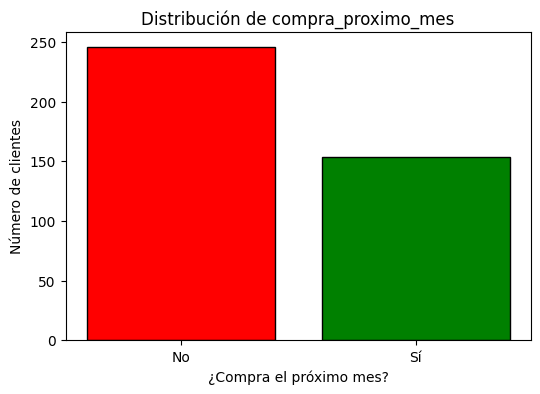

In [12]:
# TODO: gráfico de barras
conteo_target = df["compra_proximo_mes"].value_counts()

plt.figure(figsize=(6, 4))
plt.bar(conteo_target.index, conteo_target.values, color=["red", "green"], edgecolor="black")
plt.title("Distribución de compra_proximo_mes")
plt.xlabel("¿Compra el próximo mes?")
plt.ylabel("Número de clientes")
plt.show()

### Interpretación
¿Las clases aparecen aproximadamente con la misma frecuencia? Justifica con datos.

No. Hay 246 que no compran (61.5%) y 154 que sí (38.5%). No es una diferencia exagerada pero hay bastantes más "No". Si un modelo dijera siempre "No" ya acertaría el 61.5%, así que hay que tenerlo en cuenta.

## Parte 7 - Variables numéricas
### Ejercicio 14 - Estadística descriptiva
Analiza `edad`, `ingresos_anuales`, `gasto_mensual`, `num_compras` y `devoluciones`.

In [13]:
# TODO: describe() solo sobre las columnas indicadas
df[["edad", "ingresos_anuales", "gasto_mensual", "num_compras", "devoluciones"]].describe()

,edad,ingresos_anuales,gasto_mensual,num_compras,devoluciones
count,400.000000,396.000000,397.000000,400.000000,400.000000
mean,46.402500,36440.920379,69.089320,8.225000,1.225000
std,18.007809,14325.228166,39.023238,2.780955,1.136929
min,18.000000,9000.000000,5.770000,2.000000,0.000000
25%,33.000000,26034.092500,39.720000,6.000000,0.000000
50%,45.000000,36817.275000,61.170000,8.000000,1.000000
75%,59.000000,45969.032500,90.150000,10.000000,2.000000
max,195.000000,82925.370000,260.000000,17.000000,5.000000


### Interpretación
Escribe una conclusión breve para cada variable:
- **edad:** media 46.4 y mediana 45, la mitad de los clientes tiene entre 33 y 59 años. El máximo es 195, que no puede ser.
- **ingresos_anuales:** media y mediana muy parecidas (unos 36.500), así que es bastante simétrica. Va de 9000 a casi 83000 y faltan 4 valores. El mínimo de 9000 se repite mucho, es raro.
- **gasto_mensual:** la media (69.09) es mayor que la mediana (61.17), así que hay clientes que gastan mucho y tiran hacia arriba. El máximo es 260. Faltan 3.
- **num_compras:** media 8.22 y mediana 8, entre 2 y 17 compras. Bastante equilibrada.
- **devoluciones:** la mayoría hace entre 0 y 2, con media 1.23 y máximo 5.

### Ejercicio 15 - Detectar algo sospechoso
1. ¿Hay algún valor poco razonable?
2. ¿En qué variable?
3. ¿Por qué es sospechoso?
4. ¿Lo eliminarías inmediatamente?
5. ¿Qué comprobarías antes?

**Respuesta:**

1. Sí, una edad de 195.
2. En edad (cliente 20138).
3. Nadie vive 195 años y el resto está entre 18 y 75.
4. No.
5. Miraría de dónde viene el dato para ver si se puede corregir (a lo mejor era 19 o 95). Si no se puede saber, lo pondría como valor ausente para imputarlo luego en vez de borrar al cliente entero.

## Parte 8 - Distribuciones numéricas
### Ejercicio 16
Crea histogramas independientes de `edad`, `ingresos_anuales`, `gasto_mensual` y `num_compras`.

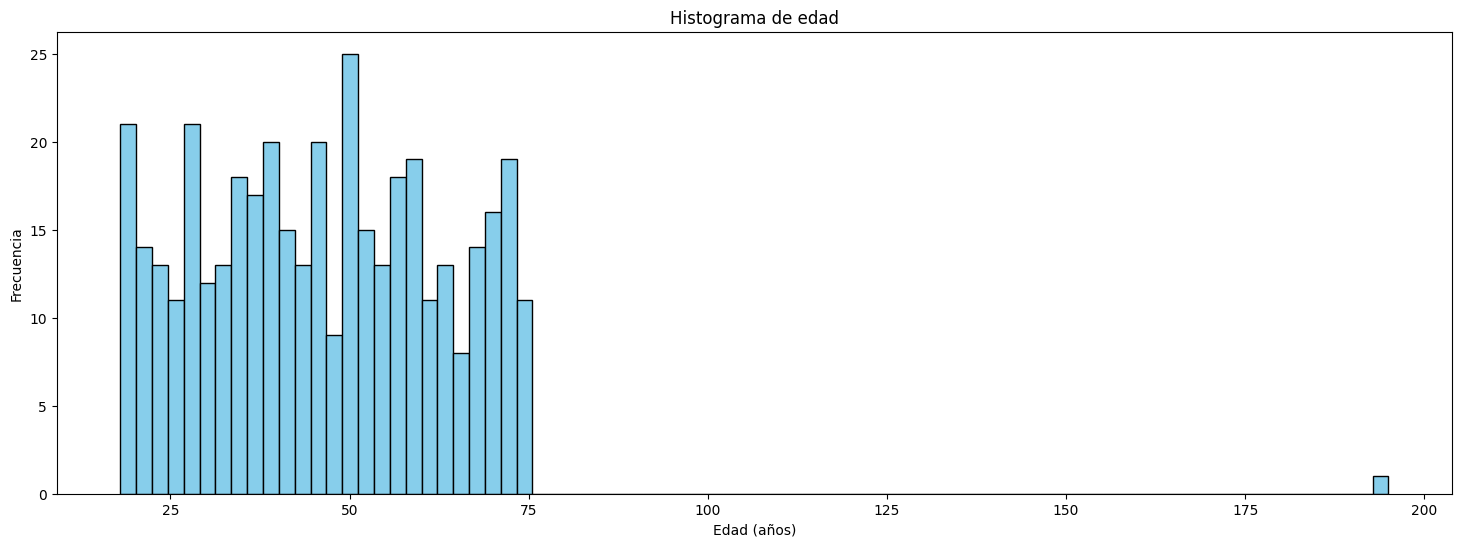

In [14]:
# TODO: histograma de edad
plt.figure(figsize=(18, 6))
plt.hist(df["edad"], bins=80, color="skyblue", edgecolor="black")
plt.title("Histograma de edad")
plt.xlabel("Edad (años)")
plt.ylabel("Frecuencia")
plt.show()

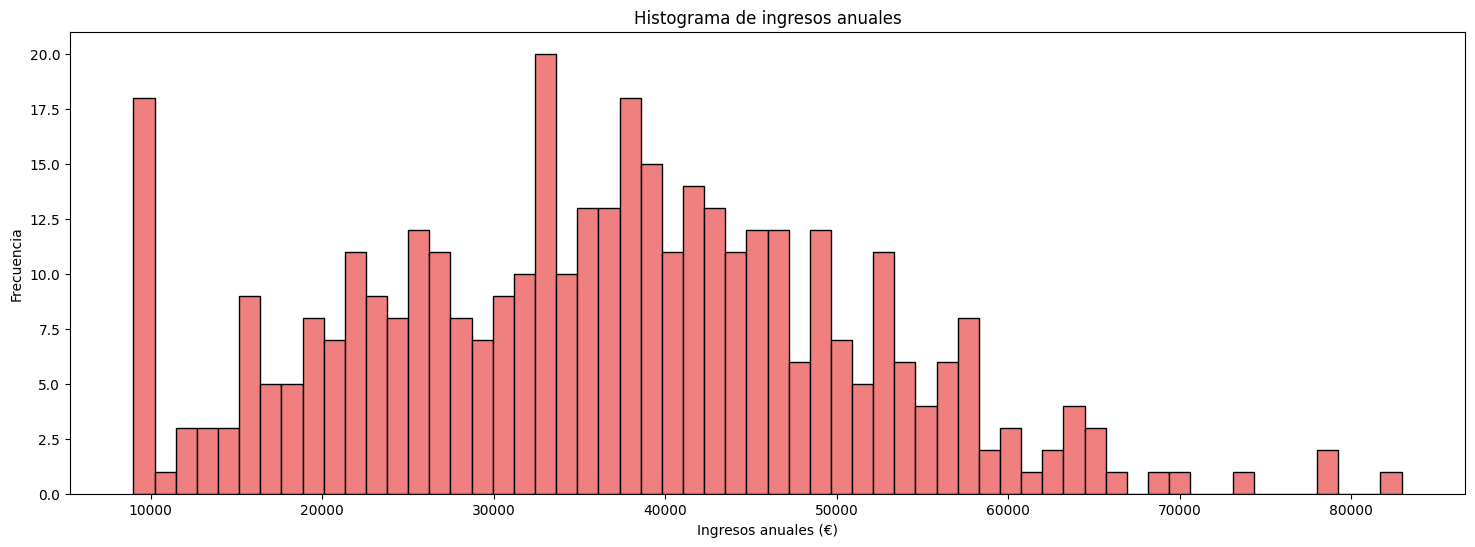

In [15]:
# TODO: histograma de ingresos_anuales
plt.figure(figsize=(18, 6))
plt.hist(df["ingresos_anuales"].dropna(), bins=60, color="lightcoral", edgecolor="black")
plt.title("Histograma de ingresos anuales")
plt.xlabel("Ingresos anuales (€)")
plt.ylabel("Frecuencia")
plt.show()

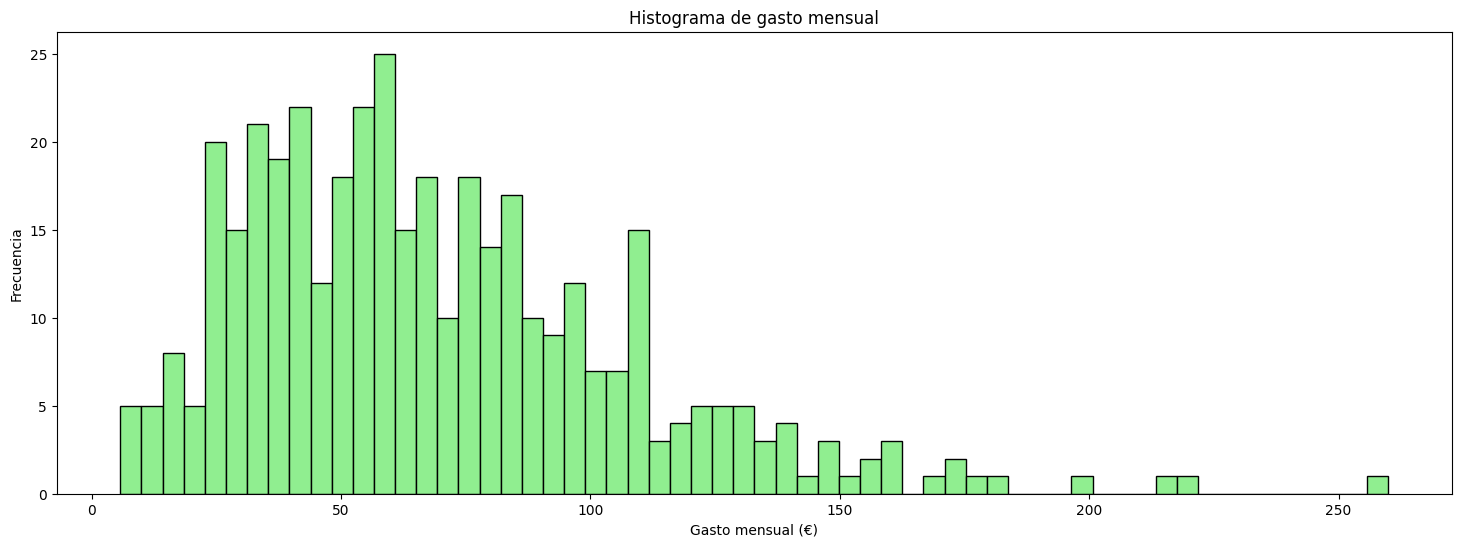

In [16]:
# TODO: histograma de gasto_mensual
plt.figure(figsize=(18, 6))
plt.hist(df["gasto_mensual"].dropna(), bins=60, color="lightgreen", edgecolor="black")
plt.title("Histograma de gasto mensual")
plt.xlabel("Gasto mensual (€)")
plt.ylabel("Frecuencia")
plt.show()

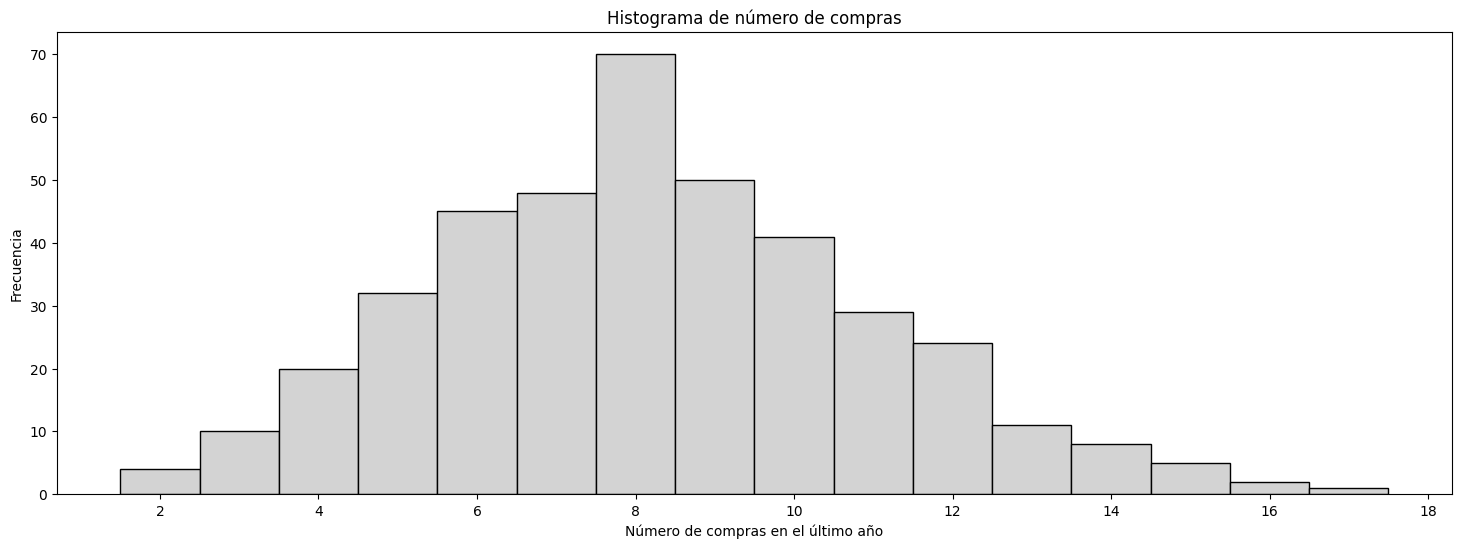

In [17]:
# TODO: histograma de num_compras
plt.figure(figsize=(18, 6))
plt.hist(df["num_compras"], bins=range(2, 19), color="lightgray", edgecolor="black", align="left")
plt.title("Histograma de número de compras")
plt.xlabel("Número de compras en el último año")
plt.ylabel("Frecuencia")
plt.show()

### Observaciones
- **edad:** casi todos entre 18 y 75, repartidos bastante igual. Hay una barra suelta a la derecha del todo (el 195) que hace que el resto se vea apretado.
- **ingresos_anuales:** tiene forma de campana, con el centro entre 35000 y 40000. Hay un pico a la izquierda por los clientes que tienen 9000 justos.
- **gasto_mensual:** la mayoría gasta entre 20 y 110 y luego hay una cola a la derecha con pocos clientes que llega hasta 260.
- **num_compras:** bastante simétrica, casi todos entre 6 y 10 y lo más repetido es 8.

## Parte 9 - Un mismo dataset, diferentes problemas
### Ejercicio 17 - Problema A
> ¿Realizará el cliente una compra el próximo mes?

Completa y justifica:
- Target: compra_proximo_mes
- ¿Existe \(y\)?: sí, la tenemos para todos los clientes
- Supervisado / no supervisado: supervisado, porque tenemos la respuesta de cada cliente
- Clasificación / regresión / clustering: clasificación, porque la respuesta es una categoría
- Binaria / multiclase: binaria, solo Sí o No

### Ejercicio 18 - Problema B
Supón una columna `gasto_proximo_mes` con cantidades monetarias.

> ¿Cuánto gastará el cliente el próximo mes?

1. ¿Cuál sería \(y\)?
2. ¿Qué tipo de variable?
3. ¿Supervisado?
4. ¿Clasificación o regresión?
5. ¿Por qué?

**Respuesta:**

1. gasto_proximo_mes
2. Numérica continua.
3. Sí.
4. Regresión.
5. Porque queremos predecir una cantidad de dinero, no una categoría.

### Ejercicio 19 - Problema C
> Descubrir grupos de clientes similares sin grupos definidos previamente.

1. ¿Existe etiqueta de grupo?
2. ¿Necesitamos \(y\)?
3. ¿Supervisado o no supervisado?
4. ¿Qué técnica usaríamos?
5. ¿Qué variables podrían describir los grupos?

**Respuesta:**

1. No.
2. No, solo X.
3. No supervisado.
4. Clustering, por ejemplo K-Means.
5. Edad, ingresos, gasto mensual, número de compras, devoluciones, antigüedad, satisfacción o nivel de fidelidad.

## Parte 10 - Razonamiento
### Ejercicio 20 - ¿Una columna puede cambiar de papel?
¿Por qué una misma variable puede actuar como característica en un problema y como objetivo en otro?

**Respuesta:** Porque depende de lo que queramos predecir. Por ejemplo, gasto_mensual aquí es una característica para saber si alguien comprará, pero si quisiéramos predecir cuánto gasta un cliente pasaría a ser el target. Lo mismo con satisfaccion.

### Ejercicio 21 - ¿Qué está mal aquí?
Un compañero hace:

```python
X = df.drop(columns=["compra_proximo_mes"])
y = df["compra_proximo_mes"]
```

y afirma que todas las columnas de `X` ya son características adecuadas.

¿Estás de acuerdo? Identifica al menos dos cuestiones que revisarías.

**Respuesta:** No.

1. Se ha dejado cliente_id dentro de X, y es un identificador.
2. Hay columnas de texto (dispositivo, zona, nivel_fidelidad) que habrá que codificar, y nivel_fidelidad tiene orden.
3. Hay valores que faltan en antigüedad, ingresos y gasto.
4. Está la edad de 195 sin revisar.

## Parte 11 - Ficha técnica
### Ejercicio 22

```text
FICHA DEL DATASET
=================
Nombre: Clientes e-commerce
Número de muestras: 400
Número de columnas: 12
Unidad de observación: cliente
Identificador: cliente_id
Target: compra_proximo_mes
Tipo de target: categórica binaria (Sí/No)
Número de features candidatas: 10
Features numéricas: edad, antiguedad_meses, ingresos_anuales, gasto_mensual, num_compras, devoluciones
Features categóricas nominales: dispositivo, zona
Features ordinales: nivel_fidelidad, satisfaccion
Datos etiquetados: sí
Valores ausentes: 12 (antiguedad_meses 5, ingresos_anuales 4, gasto_mensual 3)
Problema principal: predecir si el cliente comprará el próximo mes
Tipo de aprendizaje: supervisado
Tipo de tarea: clasificación binaria
```

## Parte 12 - Conclusiones
### Ejercicio 23
Escribe entre **10 y 15 líneas** incluyendo: muestra, dimensiones, columnas vs. features, identificador, tipos de variables, target, \(X\), \(y\), etiquetado, ausentes, distribuciones, posible problema de calidad y tipo de problema de ML.

### Conclusiones
El dataset tiene 400 muestras y cada una es un cliente. Hay 12 columnas, pero no todas son características: cliente_id es el identificador y compra_proximo_mes es el target, así que quedan 10.

Hay variables numéricas (edad, antigüedad, ingresos, gasto, compras y devoluciones), nominales (dispositivo y zona) y ordinales (nivel de fidelidad y satisfacción). Me he dado cuenta de que no se puede clasificar solo por el dtype, porque cliente_id y satisfaccion son números pero no son cantidades.

X queda con forma (400, 10) e y con (400,). Como tenemos el target de todos los clientes, el dataset está etiquetado y se puede usar para aprendizaje supervisado. Es un problema de clasificación binaria, con más "No" (61.5%) que "Sí" (38.5%).

Faltan pocos datos, 12 en total. El gasto mensual tiene cola hacia la derecha y en los ingresos hay muchos clientes con 9000 justos. El mayor problema que he visto es la edad de 195 años, que habrá que arreglar antes de entrenar nada.

# Ampliación opcional - El reto del analista
Mediante pandas, responde e interpreta:

1. ¿Qué nivel de fidelidad presenta mayor gasto mensual medio?
2. ¿El gasto histórico medio difiere entre quienes compran el mes siguiente y quienes no?
3. ¿Qué dispositivo tiene mayor número medio de compras?
4. ¿Cuál es la satisfacción media por nivel de fidelidad?
5. ¿Qué porcentaje de clientes de cada nivel compra el mes siguiente?

> Una asociación no demuestra causalidad.

In [18]:
# TODO: ampliación opcional

# 1. Gasto mensual medio por nivel de fidelidad
print("1. Gasto mensual medio por nivel de fidelidad")
print(df.groupby("nivel_fidelidad")["gasto_mensual"].mean().round(2).sort_values(ascending=False))

# 2. Gasto medio según si compran o no el mes siguiente
print("\n2. Gasto mensual medio según compra_proximo_mes")
print(df.groupby("compra_proximo_mes")["gasto_mensual"].agg(["mean", "median"]).round(2))

# 3. Número medio de compras por dispositivo
print("\n3. Número medio de compras por dispositivo")
print(df.groupby("dispositivo")["num_compras"].mean().round(2).sort_values(ascending=False))

# 4. Satisfacción media por nivel de fidelidad
print("\n4. Satisfacción media por nivel de fidelidad")
print(df.groupby("nivel_fidelidad")["satisfaccion"].mean().round(2))

# 5. Porcentaje de clientes de cada nivel que compra el mes siguiente
print("\n5. % de compra por nivel de fidelidad")
print((pd.crosstab(df["nivel_fidelidad"], df["compra_proximo_mes"], normalize="index") * 100).round(2))

1. Gasto mensual medio por nivel de fidelidad
nivel_fidelidad
Oro        70.93
Platino    69.70
Plata      68.69
Bronce     68.20
Name: gasto_mensual, dtype: float64

2. Gasto mensual medio según compra_proximo_mes
                     mean  median
compra_proximo_mes               
No                  64.59   59.28
Sí                  76.34   66.50

3. Número medio de compras por dispositivo
dispositivo
Ordenador    8.24
Tablet       8.24
Móvil        8.21
Name: num_compras, dtype: float64

4. Satisfacción media por nivel de fidelidad
nivel_fidelidad
Bronce     3.31
Oro        3.37
Plata      3.37
Platino    3.24
Name: satisfaccion, dtype: float64

5. % de compra por nivel de fidelidad
compra_proximo_mes     No     Sí
nivel_fidelidad                 
Bronce              69.14  30.86
Oro                 62.65  37.35
Plata               60.00  40.00
Platino             38.00  62.00


### Interpretación de la ampliación

1. Oro es el que más gasta de media (70.93), pero los cuatro niveles están muy cerca, entre 68 y 71.
2. Sí, los que compran el mes siguiente gastaban 76.34 de media y los que no 64.59.
3. Casi no hay diferencia, todos rondan las 8.2 compras.
4. También muy parecida en todos, entre 3.24 y 3.37.
5. Aquí sí hay diferencia: Bronce 30.86%, Oro 37.35%, Plata 40% y Platino 62%.

Lo que más destaca es lo del nivel de fidelidad, pero es solo una asociación, no quiere decir que subir de nivel a alguien le haga comprar.

# Antes de entregar
- Completa todos los `TODO`.
- Responde las preguntas en Markdown.
- Añade títulos y etiquetas a los gráficos.
- Ejecuta el notebook completo desde el principio y comprueba que no hay errores.
- Justifica tus decisiones.

**Nombre recomendado:** `Practica_04_Apellido_Nombre.ipynb`